# Stream 1: Setup, Data Prep and Exploration
**Project:** Stockout-Aware Demand Forecasting for Grocery Retail (MIS 382N)

This notebook sets up the shared workspace, loads the data, checks data quality, explores stockouts, and freezes the train/validation/test splits the other streams use.

## 1. Setup
Mounts the shared Google Drive folder and copies (or updates) the GitHub repo, so the shared code in `src/` can be imported. Requires a `GITHUB_TOKEN` secret (key icon in the left sidebar) with Notebook access turned on.

In [ ]:
from google.colab import drive, userdata
import os
drive.mount('/content/drive')

token = userdata.get('GITHUB_TOKEN')
repo = 'stockout-aware-forecasting'
if not os.path.exists(f'/content/{repo}'):
    !git clone https://{token}@github.com/bulut19/{repo}.git /content/{repo}
%cd /content/{repo}
!git pull

Mounted at /content/drive


Load the shared code and confirm the data folder and daily table are found. Run this after the setup cell every session.

In [ ]:
from src.load_data import DRIVE_DIR, load_daily, load_hourly
print(DRIVE_DIR)
print(load_daily().shape)

/content/drive/MyDrive/MIS 382 Deep Learning and ML/Final Project/Stockout Project Data
(4850000, 20)


## 2. Data
**Source:** [FreshRetailNet-50K](https://huggingface.co/datasets/Dingdong-Inc/FreshRetailNet-50K), published on Hugging Face by Dingdong-Inc (CC BY 4.0 license).
**Paper:** Wang et al. (2025), [FreshRetailNet-50K: A Stockout-Annotated Censored Demand Dataset for Latent Demand Recovery and Forecasting in Fresh Retail](https://arxiv.org/abs/2505.16319).

- 50,000 store-product series from 898 stores in 18 cities, 865 perishable products
- 90 days of training data + 7 days of evaluation data (Mar 28 to Jul 2, 2024)
- Hourly sales and hourly in-stock / out-of-stock flags, plus discount, holiday, activity and weather
- Sales are scaled quantities (no prices or units)

`download_raw()` saves the raw files to `Stockout Project Data/raw/data`. It only needs to run once.

In [ ]:
from src.load_data import download_raw, build_daily, load_daily, load_hourly

download_raw()        # only needed once
daily = build_daily() # only needed once
print(daily.shape, daily.series_id.nunique())

data/train.parquet: reconstructing file:   0%|          |  0.00B /  106MB            

data/train.parquet: downloading bytes:           |  0.00B            

data/eval.parquet: reconstructing file:   0%|          |  0.00B / 8.44MB            

data/eval.parquet: downloading bytes:           |  0.00B            

Raw files saved to /content/drive/MyDrive/Stockout Project Data/raw/data
Saved 4,850,000 rows to /content/drive/MyDrive/Stockout Project Data/processed/daily.parquet
(4850000, 19) 50000


In [ ]:
ids = daily.series_id.drop_duplicates().sample(50, random_state=1).tolist()
hourly = load_hourly(ids)
hourly.head()

,series_id,dt,hour,sales,out_of_stock,split
0,34_740,2024-03-28,0,0.0,1,train
1,34_740,2024-03-28,1,0.0,1,train
2,34_740,2024-03-28,2,0.0,1,train
3,34_740,2024-03-28,3,0.0,1,train
4,34_740,2024-03-28,4,0.0,0,train


**Recap:** `load_hourly()` returns one row per product per hour, with `sales` and `out_of_stock` (1 = shelf empty that hour). Load it only for selected products (e.g. the 2,000-series sample), since all 50,000 series is about 116M rows.

**Note:** Overnight hours often show out of stock. These are evening stockouts lasting until the morning restock, and overnight sales are near zero. The dataset's own stockout count only covers **6:00 to 22:00**, so we treat those as selling hours when measuring stockouts and missed demand.

## 3. Shared metrics
Every stream scores results with `src/metrics.py`, so all numbers are comparable:
- **WAPE:** overall forecast error as a percentage
- **MAE:** average error in sales units
- **Bias:** negative = under-forecasting (key for the stockout story)
- **Pinball loss:** quality of forecast ranges, used by the ordering simulator
- **Recovery error:** how well hidden hours are filled in (Stream 2)

In [ ]:
from src.metrics import wape, mae, bias, pinball, score
import numpy as np

actual = np.array([10, 0, 5, 5])
pred   = np.array([8, 1, 5, 6])
print(wape(actual, pred), mae(actual, pred), bias(actual, pred))

0.2 1.0 0.0


**Recap:** Metrics work as expected on a toy example: 20% error (WAPE), 1 unit average miss (MAE), and no overall bias.

## 4. Data quality checks
Before exploring, we confirm the data is complete and internally consistent: every product has all days, nothing is missing, values are sensible, and the hourly and daily numbers agree.

In [ ]:
daily = load_daily()

days = daily.groupby(['series_id', 'split']).size().unstack()
print(days.value_counts())
print('Duplicate series-day rows:', daily.duplicated(['series_id', 'dt']).sum())
print('Date range:', daily.dt.min().date(), 'to', daily.dt.max().date())
print('Missing values:', daily.isna().sum().sum())

eval  train
7     90       50000
Name: count, dtype: int64
Duplicate series-day rows: 0
Date range: 2024-03-28 to 2024-07-02
Missing values: 0


In [ ]:
cols = ['sale_amount', 'stock_hour6_22_cnt', 'discount', 'precpt', 'avg_temperature', 'avg_humidity', 'avg_wind_level']
display(daily[cols].describe().T.round(3))

print('Negative sales:', (daily.sale_amount < 0).sum())
print('Discount = 0:', (daily.discount == 0).sum())
print('Discount > 1:', (daily.discount > 1).sum())

z = daily[daily.discount == 0]
print('Discount = 0 rows: series affected', z.series_id.nunique(),
      '| avg sales', round(z.sale_amount.mean(), 2), 'vs overall', round(daily.sale_amount.mean(), 2))

,count,mean,std,min,25%,50%,75%,max
sale_amount,4850000.0,1.013,1.450,0.00,0.400,0.700,1.100,49.900
stock_hour6_22_cnt,4850000.0,3.160,4.587,0.00,0.000,0.000,6.000,16.000
discount,4850000.0,0.912,0.128,0.00,0.851,0.991,1.000,1.088
precpt,4850000.0,3.856,3.655,0.00,1.494,2.424,5.073,42.500
avg_temperature,4850000.0,22.765,3.886,12.06,19.650,22.840,26.070,32.290
avg_humidity,4850000.0,74.742,9.886,27.35,71.970,76.600,80.770,100.000
avg_wind_level,4850000.0,1.720,0.384,0.97,1.440,1.620,1.930,3.850


Negative sales: 0
Discount = 0: 17339
Discount > 1: 34
Discount = 0 rows: series affected 253 | avg sales 15.13 vs overall 1.01


In [ ]:
check_ids = daily.series_id.drop_duplicates().sample(200, random_state=42).tolist()
hourly = load_hourly(check_ids)

h_sum = hourly.groupby(['series_id', 'dt']).sales.sum()
d = daily.set_index(['series_id', 'dt']).loc[h_sum.index]
print('Max gap, hourly sum vs daily sales:', float((h_sum - d.sale_amount).abs().max()))

oos = hourly[hourly.hour.between(6, 21)].groupby(['series_id', 'dt']).out_of_stock.sum()
print('Stockout count matches hours 6 to 21:', bool((oos == d.stock_hour6_22_cnt).all()))

Max gap, hourly sum vs daily sales: 3.552713678800501e-15
Stockout count matches hours 6 to 21: True


In [ ]:
by_hour = hourly.groupby('hour').agg(share_out_of_stock=('out_of_stock', 'mean'),
                                     avg_sales=('sales', 'mean')).round(3)
by_hour

,share_out_of_stock,avg_sales
hour,,
0,0.417,0.009
1,0.404,0.005
2,0.376,0.003
3,0.329,0.003
4,0.269,0.003
5,0.174,0.010
6,0.056,0.035
7,0.043,0.069
8,0.051,0.101


**Findings from the data checks:**
- **Complete:** all 50,000 products have 90 training days + 7 evaluation days; no duplicates or missing values.
- **Consistent:** hourly sales add up exactly to daily sales, and the dataset's stockout count matches the hourly flags for hours 6 to 21 (16 selling hours).
- **Stockouts build through the day:** about 6% of products are out of stock at 6am, rising to about 42% by 9pm. Overnight flags are mostly evening stockouts carrying over until the morning restock, and overnight sales are near zero, so we use **6:00 to 22:00** as selling hours.
- **Discount = 0 on 17,339 rows (0.36%, 253 products):** these days all have sales, averaging about 15x the overall average, so they are not free products. We treat discount = 0 as missing and add a `discount_missing` flag.
- **34 rows have discount slightly above 1:** a small price increase; kept as is.

In [ ]:
import importlib
import src.load_data
importlib.reload(src.load_data)   # picks up the edited file without restarting
from src.load_data import build_daily, load_daily

daily = build_daily()
print('Rows flagged:', daily.discount_missing.sum())

Saved 4,850,000 rows to /content/drive/MyDrive/Stockout Project Data/processed/daily.parquet
Rows flagged: 17339


**Recap:** Daily table resaved with the discount fix: discount = 0 is now missing (NaN), with a `discount_missing` flag on 17,339 rows.

## 5. Stockout exploration
How often shelves go empty, when, for how long, and whether it happens when demand is high. Hourly charts use a random sample of 1,000 products and only selling hours (6:00 to 22:00).

In [ ]:
import os
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

plt.rcParams.update({'figure.figsize': (8, 4), 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.3})
BLUE, ORANGE = '#2b6cb0', '#dd6b20'
from src.load_data import DRIVE_DIR
FIG_DIR = DRIVE_DIR / 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

daily = load_daily()
daily['any_stockout'] = daily.stock_hour6_22_cnt > 0
daily['zero_sales'] = daily.sale_amount == 0

eda_ids = daily.series_id.drop_duplicates().sample(1000, random_state=7).tolist()
hourly = load_hourly(eda_ids)
hourly = hourly[hourly.hour.between(6, 21)]   # selling hours only
print(f'{len(daily):,} daily rows | {len(hourly):,} hourly rows for {len(eda_ids)} products')

4,850,000 daily rows | 1,552,000 hourly rows for 1000 products


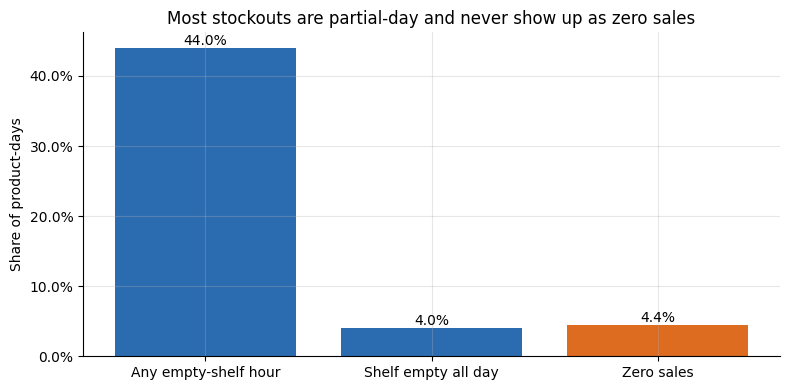

Zero-sales days that had a stockout: 76.4%


In [ ]:
any_so = daily.any_stockout.mean()
full = (daily.stock_hour6_22_cnt == 16).mean()
zero = daily.zero_sales.mean()

fig, ax = plt.subplots()
bars = ax.bar(['Any empty-shelf hour', 'Shelf empty all day', 'Zero sales'], [any_so, full, zero],
              color=[BLUE, BLUE, ORANGE])
ax.bar_label(bars, labels=[f'{v:.1%}' for v in [any_so, full, zero]])
ax.set_ylabel('Share of product-days'); ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('Most stockouts are partial-day and never show up as zero sales')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_1_partial_vs_zero.png', dpi=150); plt.show()

print(f'Zero-sales days that had a stockout: {daily.loc[daily.zero_sales, "any_stockout"].mean():.1%}')

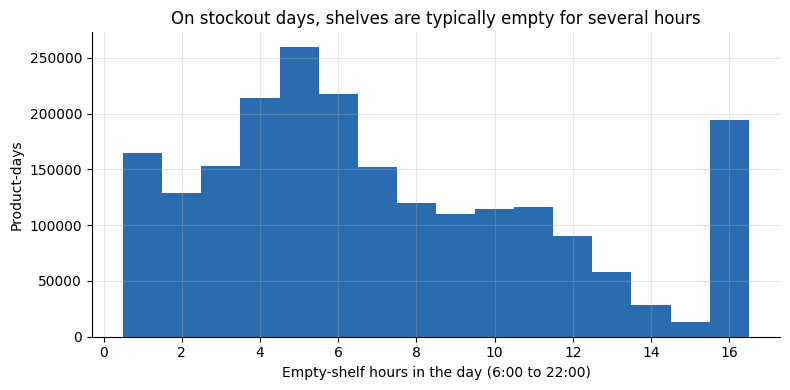

Median empty hours on stockout days: 6


In [ ]:
so_days = daily[daily.any_stockout]
fig, ax = plt.subplots()
ax.hist(so_days.stock_hour6_22_cnt, bins=np.arange(0.5, 17.5, 1), color=BLUE)
ax.set_xlabel('Empty-shelf hours in the day (6:00 to 22:00)'); ax.set_ylabel('Product-days')
ax.set_title('On stockout days, shelves are typically empty for several hours')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_2_stockout_hours.png', dpi=150); plt.show()

print(f'Median empty hours on stockout days: {so_days.stock_hour6_22_cnt.median():.0f}')

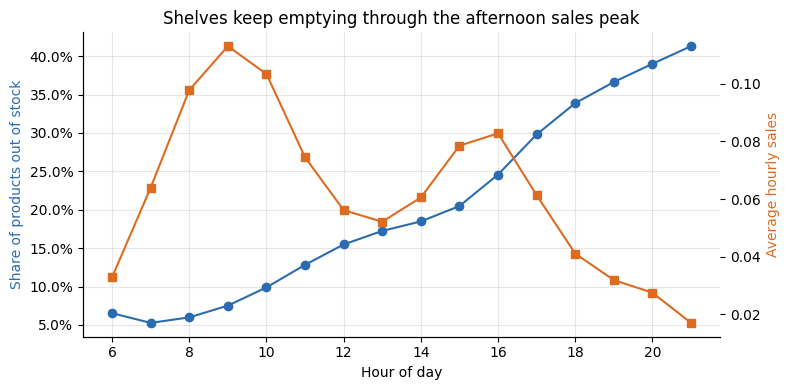

In [ ]:
by_hour = hourly.groupby('hour').agg(out_of_stock=('out_of_stock', 'mean'), sales=('sales', 'mean'))
fig, ax1 = plt.subplots()
ax1.plot(by_hour.index, by_hour.out_of_stock, color=BLUE, marker='o')
ax1.set_ylabel('Share of products out of stock', color=BLUE); ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax2 = ax1.twinx(); ax2.plot(by_hour.index, by_hour.sales, color=ORANGE, marker='s'); ax2.grid(False)
ax2.set_ylabel('Average hourly sales', color=ORANGE)
ax1.set_xlabel('Hour of day'); ax1.set_xticks(range(6, 22, 2))
ax1.set_title('Shelves keep emptying through the afternoon sales peak')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_3_by_hour.png', dpi=150); plt.show()

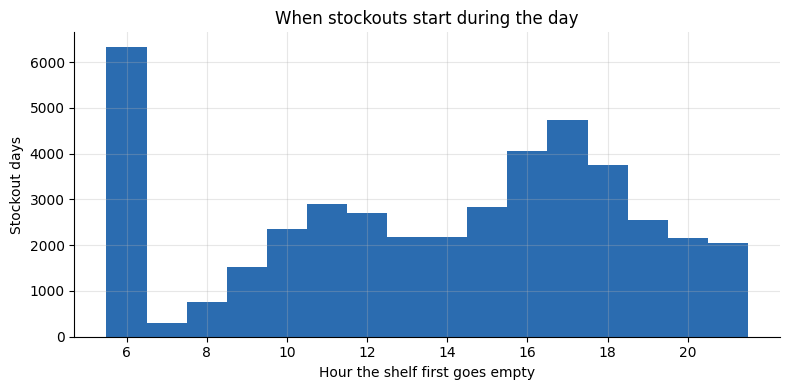

Stockouts already present at opening (6:00): 14.6%


In [ ]:
h = hourly.sort_values(['series_id', 'dt', 'hour'])
first_out = h[h.out_of_stock == 1].groupby(['series_id', 'dt']).hour.min()

fig, ax = plt.subplots()
ax.hist(first_out, bins=np.arange(5.5, 22.5, 1), color=BLUE)
ax.set_xlabel('Hour the shelf first goes empty'); ax.set_ylabel('Stockout days'); ax.set_xticks(range(6, 22, 2))
ax.set_title('When stockouts start during the day')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_4_stockout_start.png', dpi=150); plt.show()

print(f'Stockouts already present at opening (6:00): {(first_out == 6).mean():.1%}')

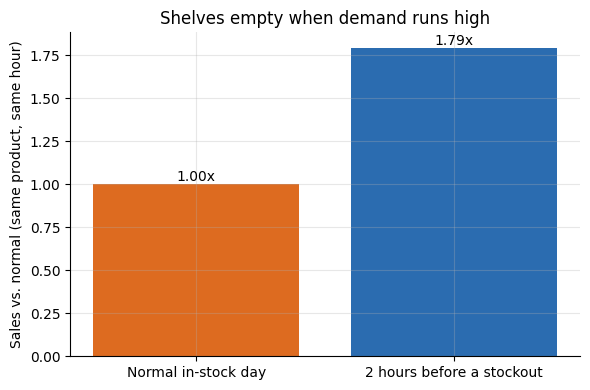

Sales in the 2 hours before a stockout: 1.79x normal


In [ ]:
day_flags = h.groupby(['series_id', 'dt']).out_of_stock.sum().rename('oos_hours').reset_index()
h2 = h.merge(day_flags, on=['series_id', 'dt'])
normal = h2[h2.oos_hours == 0].groupby(['series_id', 'hour']).sales.mean().rename('normal_sales')

fo = first_out.rename('start').reset_index()
fo = fo[fo.start >= 8]
pre = h2.merge(fo, on=['series_id', 'dt'])
pre = pre[(pre.hour >= pre.start - 2) & (pre.hour < pre.start)]
pre = pre.join(normal, on=['series_id', 'hour']).dropna(subset=['normal_sales'])
ratio = pre.sales.sum() / pre.normal_sales.sum()

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Normal in-stock day', '2 hours before a stockout'], [1, ratio], color=[ORANGE, BLUE])
ax.bar_label(bars, labels=['1.00x', f'{ratio:.2f}x'])
ax.set_ylabel('Sales vs. normal (same product, same hour)')
ax.set_title('Shelves empty when demand runs high')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_5_demand_before_stockout.png', dpi=150); plt.show()

print(f'Sales in the 2 hours before a stockout: {ratio:.2f}x normal')

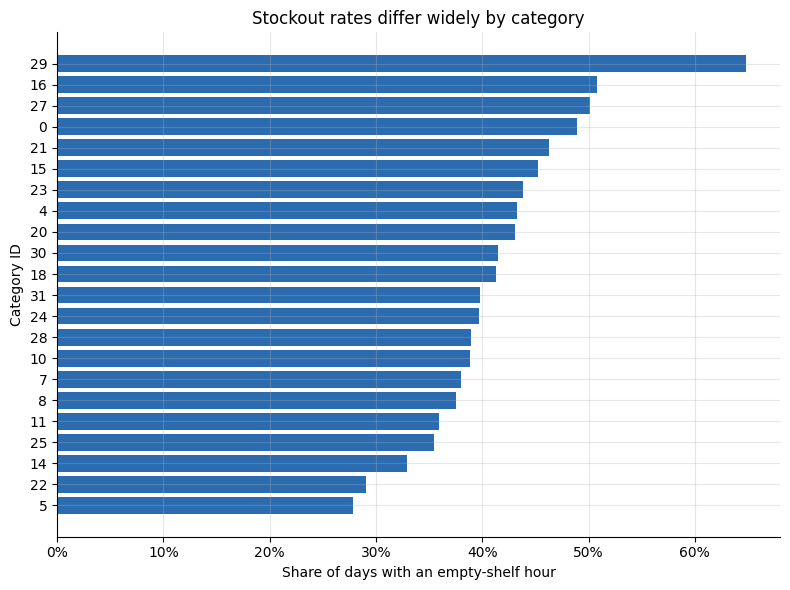

Store stockout rates: 34% to 88% (middle half 42% to 46%)


In [ ]:
cat = daily.groupby('first_category_id').agg(stockout_rate=('any_stockout', 'mean'),
                                             products=('series_id', 'nunique'))
cat = cat[cat.products >= 100].sort_values('stockout_rate')

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(cat.index.astype(str), cat.stockout_rate, color=BLUE)
ax.set_xlabel('Share of days with an empty-shelf hour'); ax.set_ylabel('Category ID')
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_title('Stockout rates differ widely by category')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_6_by_category.png', dpi=150); plt.show()

store = daily.groupby('store_id').any_stockout.mean()
print(f'Store stockout rates: {store.min():.0%} to {store.max():.0%} (middle half {store.quantile(.25):.0%} to {store.quantile(.75):.0%})')

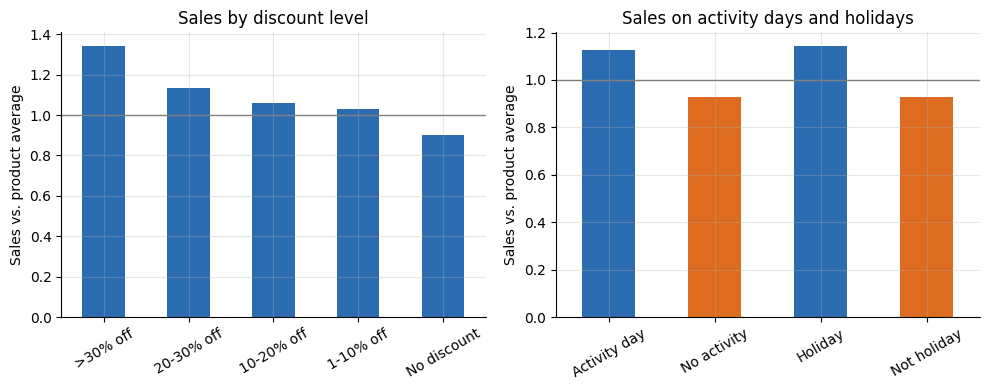

In [ ]:
instock = daily[~daily.any_stockout].copy()
instock['rel_sales'] = instock.sale_amount / instock.groupby('series_id').sale_amount.transform('mean')
instock['discount_band'] = pd.cut(instock.discount, [0, 0.7, 0.8, 0.9, 0.99, 1.1],
                                  labels=['>30% off', '20-30% off', '10-20% off', '1-10% off', 'No discount'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
instock.groupby('discount_band', observed=True).rel_sales.mean().plot.bar(ax=axes[0], color=BLUE)
axes[0].set_title('Sales by discount level'); axes[0].set_xlabel('')
flags = pd.Series({'Activity day': instock[instock.activity_flag == 1].rel_sales.mean(),
                   'No activity': instock[instock.activity_flag == 0].rel_sales.mean(),
                   'Holiday': instock[instock.holiday_flag == 1].rel_sales.mean(),
                   'Not holiday': instock[instock.holiday_flag == 0].rel_sales.mean()})
flags.plot.bar(ax=axes[1], color=[BLUE, ORANGE, BLUE, ORANGE]); axes[1].set_title('Sales on activity days and holidays')
for a in axes:
    a.axhline(1, color='gray', lw=1); a.set_ylabel('Sales vs. product average'); a.tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_7_discount_flags.png', dpi=150); plt.show()

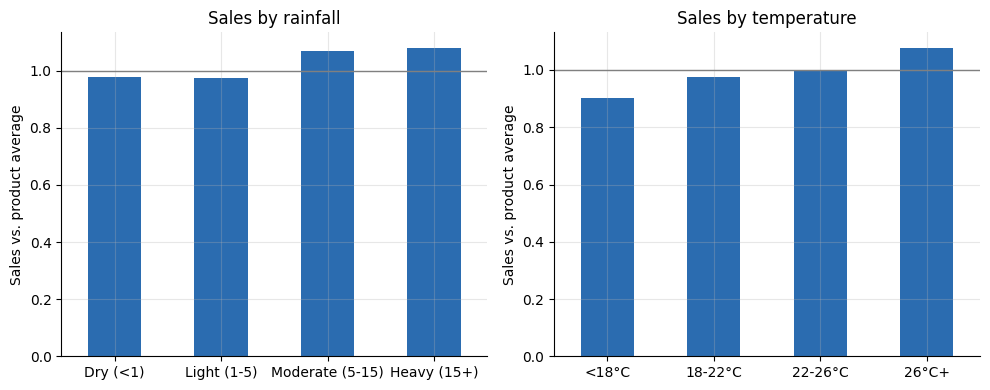

In [ ]:
instock['rain_band'] = pd.cut(instock.precpt, [-0.1, 1, 5, 15, 50],
                              labels=['Dry (<1)', 'Light (1-5)', 'Moderate (5-15)', 'Heavy (15+)'])
instock['temp_band'] = pd.cut(instock.avg_temperature, [0, 18, 22, 26, 40],
                              labels=['<18°C', '18-22°C', '22-26°C', '26°C+'])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
instock.groupby('rain_band', observed=True).rel_sales.mean().plot.bar(ax=axes[0], color=BLUE)
instock.groupby('temp_band', observed=True).rel_sales.mean().plot.bar(ax=axes[1], color=BLUE)
axes[0].set_title('Sales by rainfall'); axes[1].set_title('Sales by temperature')
for a in axes:
    a.axhline(1, color='gray', lw=1); a.set_ylabel('Sales vs. product average'); a.set_xlabel(''); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/5_8_weather.png', dpi=150); plt.show()

**Findings from the stockout exploration:**
- **Stockouts are common and mostly partial-day:** 44% of product-days have at least one empty-shelf hour, but only 4% are empty all day and only 4.4% show zero sales. 76% of zero-sales days had a stockout. Daily sales data hides most stockouts.
- **They last hours, not minutes:** on stockout days, shelves are empty for a median of 6 selling hours.
- **They build through the day:** about 6% of products are out of stock in the morning, rising to about 41% by 9pm, so afternoon and evening demand is lost most often. 15% of stockout days start with the shelf already empty at opening.
- **Shelves empty when demand is high:** sales in the 2 hours before a stockout run **1.79x** the same product's normal sales at that hour. Simply averaging normal days would underestimate missed demand.
- **Big differences across categories and stores:** category stockout rates range from about 28% to 65%; most stores sit between 42% and 46%.
- **Demand drivers (in-stock days):** sales rise with deeper discounts (+34% vs. product average at >30% off), and run about 13 to 14% higher on activity days and holidays. Warmer and rainier days show somewhat higher sales, but temperature also rises from March to July, so part of that is a seasonal trend, not weather.

## 6. Modeling table and frozen splits
Adds the columns every stream needs and assigns each day to train, validation or test. The splits are fixed by date so no model ever trains on future data.

| Set | Dates (2024) | Days |
|---|---|---|
| Train | Mar 28 to Jun 11 | 76 |
| Validation | Jun 12 to Jun 25 | 14 |
| Test | Jun 26 to Jul 2 (official evaluation set) | 7 |

In [ ]:
import numpy as np, pandas as pd
from src.load_data import PROC_DIR

model = load_daily()
model['any_stockout'] = (model.stock_hour6_22_cnt > 0).astype('int8')   # what hourly data shows
model['zero_sales_day'] = (model.sale_amount == 0).astype('int8')       # what a daily system would flag
model['day_of_week'] = model.dt.dt.dayofweek                             # 0 = Monday

VALID_START, TEST_START = pd.Timestamp('2024-06-12'), pd.Timestamp('2024-06-26')
model['set'] = np.select([model.dt < VALID_START, model.dt < TEST_START], ['train', 'valid'], 'test')
model.groupby('set').dt.agg(['min', 'max', 'nunique'])

,min,max,nunique
set,,,
test,2024-06-26,2024-07-02,7
train,2024-03-28,2024-06-11,76
valid,2024-06-12,2024-06-25,14


## 7. The 2,000-series sample
Heavier models (TFT, foundation models, fine-tuning) all run on the same 2,000 products so results are comparable. The sample keeps the full dataset's mix of categories and stockout levels (low / medium / high, based on the training period only).

In [ ]:
train = model[model.set == 'train']
rates = train.groupby('series_id').agg(stockout_rate=('any_stockout', 'mean'),
                                       category=('first_category_id', 'first'))
rates['stockout_band'] = pd.qcut(rates.stockout_rate, 3, labels=['low', 'medium', 'high'])

sample = rates.groupby(['category', 'stockout_band'], observed=True).sample(frac=2000 / len(rates), random_state=42)
if len(sample) > 2000:
    sample = sample.sample(2000, random_state=42)
elif len(sample) < 2000:
    sample = pd.concat([sample, rates.drop(sample.index).sample(2000 - len(sample), random_state=42)])

print('Sample size:', len(sample))
print('Avg stockout rate: all', round(rates.stockout_rate.mean(), 3), '| sample', round(sample.stockout_rate.mean(), 3))
print('Categories covered:', sample.category.nunique(), 'of', rates.category.nunique())
pd.DataFrame({'all 50,000': rates.stockout_band.value_counts(normalize=True),
              'sample': sample.stockout_band.value_counts(normalize=True)}).round(3)

Sample size: 2000
Avg stockout rate: all 0.444 | sample 0.446
Categories covered: 28 of 32


,"all 50,000",sample
stockout_band,,
low,0.356,0.357
medium,0.333,0.334
high,0.311,0.310


In [ ]:
model['in_sample'] = model.series_id.isin(sample.index).astype('int8')

sample.reset_index()[['series_id', 'category', 'stockout_rate', 'stockout_band']].to_csv(PROC_DIR / 'sample_ids.csv', index=False)
model.to_parquet(PROC_DIR / 'daily_model.parquet', index=False)
print(f'Saved daily_model.parquet ({len(model):,} rows, {model.shape[1]} columns) and sample_ids.csv')

Saved daily_model.parquet (4,850,000 rows, 25 columns) and sample_ids.csv


**Recap:** Saved two files for the team in `processed/`:
- `daily_model.parquet`: the daily table plus `any_stockout`, `zero_sales_day`, `day_of_week`, `set` (train / valid / test) and `in_sample`.
- `sample_ids.csv`: the 2,000 products used for heavy models. The sample matches the full data on stockout rate (44.6% vs. 44.4%) and covers 28 of 32 categories; the 4 missing categories have very few products.

In [3]:
import glob, os
os.chdir('/content/stockout-aware-forecasting')   # run git inside the repo

found = glob.glob('/content/drive/MyDrive/MIS 382 Deep Learning and ML/Final Project/Notebooks/*.ipynb')
print(found)

FileNotFoundError: [Errno 2] No such file or directory: '/content/stockout-aware-forecasting'